# 02 · Inspect trajectories and regime coverage

Inspect training data only before model fitting. Each plot can be regenerated independently after setup and loading.

**Run cells in order.** The default smoke preset validates the pipeline; it is too small for a scientific conclusion.

## Setup

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'twilight_moe').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'twilight_moe').exists(), 'Start Jupyter from the project folder'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from twilight_moe.config import load_config, run_dir
from twilight_moe.plotting import style, save_figure, COLORS
cfg = load_config()
style()
print('Preset:', cfg['name'], '| seeds:', cfg['seeds'])
print('Dataset root:', cfg['data_root'])

Preset: experiment | seeds: [7, 17, 27]
Dataset root: E:/HarunoKen/Twilight_MoE_Dynamics


## Load the training split

No test data are used to choose settings.

In [2]:
from twilight_moe.data import load_data
data, normalization = load_data(cfg, cfg['seeds'][0])
x, r = data['train']['states'], data['train']['regimes']

## Plot one sequence

The regime panel identifies the transition applied at time t.

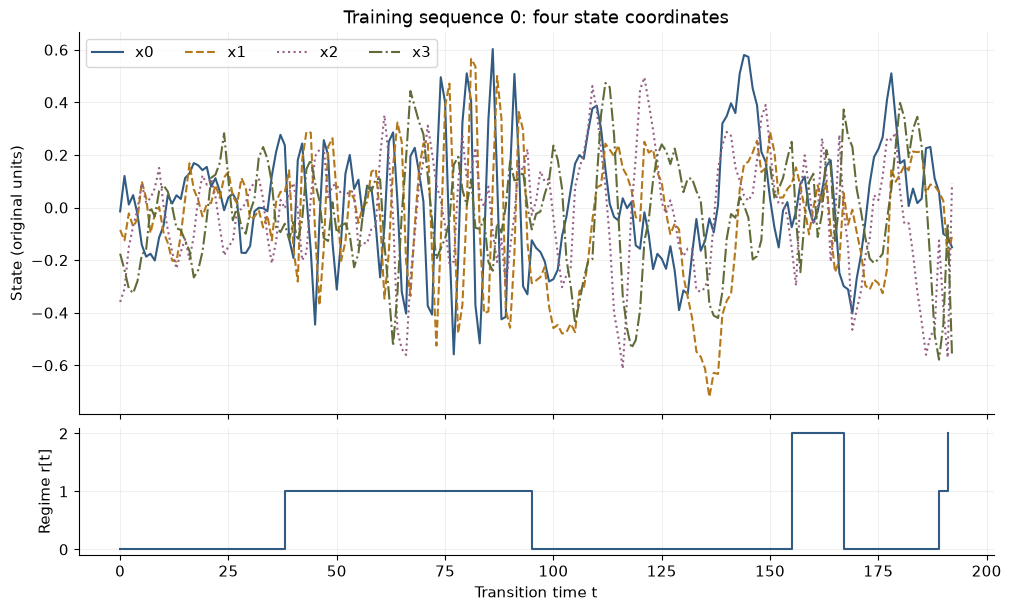

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[3, 1])
for j, (color, line) in enumerate(zip(['#315b83', '#b47719', '#965f86', '#606c38'], ['-', '--', ':', '-.'])):
    axes[0].plot(x[0, :, j], color=color, linestyle=line, label=f'x{j}')
axes[0].set(title='Training sequence 0: four state coordinates', ylabel='State (original units)')
axes[0].legend(ncol=4)
axes[1].step(np.arange(len(r[0])), r[0], where='post', color='#315b83')
axes[1].set(xlabel='Transition time t', ylabel='Regime r[t]', yticks=[0, 1, 2])
save_figure(fig, cfg, 'training_trajectory')
plt.show()

## Plot regime coverage

Coverage is measured over training transitions, including all sequences.

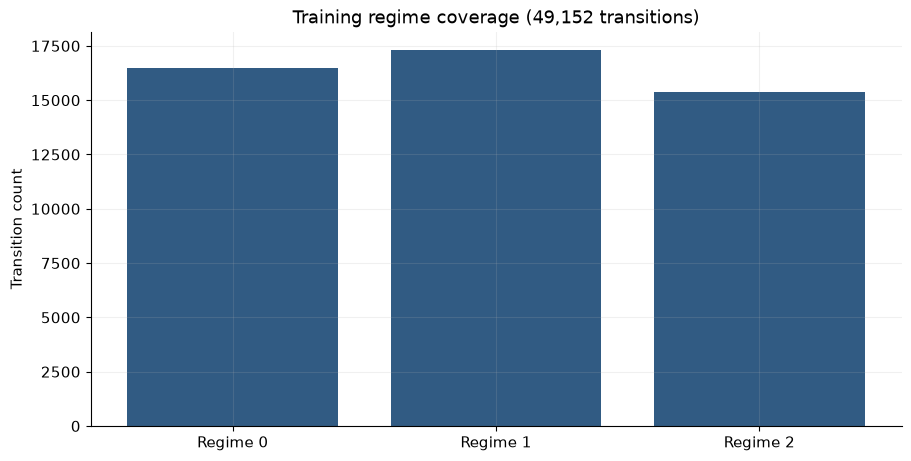

Observed switch fraction: 0.05155840968586387
Configured switch probability: 0.050000000000000044


In [4]:
counts = np.bincount(r.ravel(), minlength=3)
fig, ax = plt.subplots()
ax.bar(['Regime 0', 'Regime 1', 'Regime 2'], counts, color='#315b83')
ax.set(title=f'Training regime coverage ({r.size:,} transitions)', ylabel='Transition count')
save_figure(fig, cfg, 'regime_coverage')
plt.show()
print('Observed switch fraction:', np.mean(r[:, 1:] != r[:, :-1]))
print('Configured switch probability:', 1-cfg['data']['stay_probability'])

## Interpretation

A single trajectory is illustrative. Use aggregate coverage to check for absent regimes. Different runs need not have exactly equal counts.